# Trajectory Optimization 실습 — *비용 함수를 직접 튜닝하고 구현하기*
## 미션: 파란 차가 **초록 reference path**를 따라가고 **빨간 차**를 피하게 만들어라!

이 실습의 방식은 간단합니다.

> **비용 함수의 weight를 바꾸거나 제약을 켤 때마다, 화면에 [트랙 그림 + 결과(PASS/FAIL)]가 같이 나옵니다.**
> 빨간 ✗ 가 초록 ✓ 로 바뀌도록 숫자와 제약 조건을 고쳐가며, optimization trajectory planning을 몸으로 익힙니다.

결과는 4가지는 다음과 같습니다.

| 항목 | 의미 |
|---|---|
| **Tracking** | 초록 reference path를 잘 따라가는가 |
| **On-road** | 도로 밖으로 나가지 않는가 |
| **No-collision** | 장애물과 부딪히지 않는가 |
| **Comfort** | 급조향(조향 변화율 δ̇) 없이 부드러운가 |

먼저 *실패 case* 들로 "이렇게 하면 실패한다"를 보고,
그다음 **수강생 분들이 직접** 같은 case를 다시 살려 봅니다.
마지막에는 비용 항을 직접 채워서 이론식과 코드가 어떻게 연결되는지 확인합니다.

라이브러리는 `numpy`, `scipy`, `matplotlib` 뿐입니다.


---
# Optimization Trajectory Planning 이론 흐름

**Trajectory planning이란?**
- 차가 앞으로 몇 초 동안 **어떤 궤적으로 움직일지**를 정하는 것
- 지도 위의 선 하나가 아니라, 시간에 따른 **위치·방향·속도** + 그것을 만드는 **가속도·조향**을 함께 결정

**최적화 문제로 보면:**

$$
\begin{aligned}
\min_{\mathbf{u}_{0:N-1}} \quad & J(\mathbf{x}_{0:N}, \mathbf{u}_{0:N-1}) \\
\text{s.t.} \quad
& \mathbf{x}_{k+1}=f(\mathbf{x}_k, \mathbf{u}_k) \\
& \mathbf{u}_{min} \le \mathbf{u}_k \le \mathbf{u}_{max}
\end{aligned}
$$

- **고른다** → control sequence $u_{0:N-1}$ (각 $u_k=\dot\delta_k$, 조향 변화율 / 속도는 고정 = 횡방향만 최적화)
- **만든다** → bicycle model이 그 control로 미래 trajectory 생성
- **점수 매긴다** → cost function $J$ 로 trajectory가 얼마나 좋은지 평가
- **찾는다** → solver가 *cost는 최소, constraint는 만족* 하는 해를 탐색

> **constraint(제약, s.t. = "단, 아래를 지키며")** =
> ① 차는 **bicycle model 대로만** 움직임 ($\mathbf{x}_{k+1}=f(\mathbf{x}_k,\mathbf{u}_k)$)  
> ② 가속도·조향각이 **물리적 한계 안** ($\mathbf{u}_{min}\le\mathbf{u}_k\le\mathbf{u}_{max}$)  
> ③ **충돌·도로 이탈 금지**(안전). (자세한 건 4·5절)

**planning에 필요한 4가지 재료**

| 재료 | 역할 | 한 줄 요약 |
|---|---|---|
| **① Reference path** | 가고 싶은 목표선 | "이쪽으로 가고 싶다" (절대 명령 ✗) |
| **② Vehicle model** | control → trajectory 예측 | "이 조작이면 차가 여기로 간다" |
| **③ Cost function** | 좋은 궤적의 기준 (soft) | "경로 추종(y,θ) + 조향 부드럽게" |
| **④ Constraint** | 반드시 지킬 선 (hard) | "충돌·도로이탈·제어한계 금지" |

cost function은 뒤에서 이렇게 생겼습니다 (자세한 건 3절):

$$
J = \underbrace{w_{track}\overline{(y-y_{ref})^2}+w_{heading}\overline{(\theta-\theta_{ref})^2}}_{\text{추종}}
  + \underbrace{w_{steer}\,\overline{\delta^2}}_{\text{조향각}}
  + \underbrace{w_{comfort}\,\overline{\dot\delta^2}}_{\text{control input = 조향 변화율}}
$$

**이 실습의 진행 순서**
1. reference path를 생성한다
2. bicycle model로 trajectory가 생성되는 원리를 본다
3. cost + constraint로 solver가 궤적을 만드는 과정을 본다
4. *일부러 실패하는 case* 로 weight와 constraint의 역할을 분리해 이해한다
5. 직접 실패 case를 고치고, 비용 항을 구현한다

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms

from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle, FancyBboxPatch, Rectangle
from scipy.optimize import minimize
from IPython.display import HTML

plt.rcParams['figure.dpi'] = 110
np.set_printoptions(precision=3, suppress=True)

import matplotlib.font_manager as fm

font_candidates = ['Malgun Gothic','AppleGothic','NanumGothic','Noto Sans CJK KR']

available_fonts = [font.name for font in fm.fontManager.ttflist]

for font_name in font_candidates:
    if font_name in available_fonts:
        plt.rcParams['font.family'] = font_name
        plt.rcParams['axes.unicode_minus'] = False
        break

print('준비 완료')


준비 완료


---
# *실제 planning 코드*

지금까지 설명한 이론을 **그 순서 그대로 코드로** 옮긴 부분입니다.

**어떻게 보면 되나**
- 각 코드 셀은 앞 이론의 **한 단계와 1:1로 대응** 합니다.
- "이론에서 본 개념이 코드로는 이렇게 생겼구나" 를 확인하는 게 목표 — 지금 코드를 외울 필요는 없습니다.

| 순서 | 코드 셀 | 이론에서 본 것 |
|---|---|---|
| 0 | 공통 상수 | `dt`, `N`, 차선 등 기본 설정 |
| 1 | Reference & Scenario | 따라갈 목표 경로 + 장애물 |
| 2 | Bicycle model | control → 미래 trajectory |
| 3 | Cost function | 좋은 궤적의 점수 (soft) |
| 4 | Hard constraint | 절대 지킬 선 (충돌·도로·제어한계) |
| 5 | Solver | 위를 묶어 최적 control 찾기 |

> 차·도로를 **그리는 코드**, 그리고 **채점(scorecard) 코드** 는 *뒤쪽에 따로* 모아 두었습니다.
> 지금은 **계획이 어떻게 계산되는지(위 0~5)** 에만 집중하세요. 그림 코드는 결과를 눈으로 보기 위한 도구일 뿐입니다.

## 0. 공통 상수 — 수식 기호를 코드 변수로

| 이론 기호 | 코드 변수 | 의미 |
|---|---|---|
| $\Delta t$ | `dt` | discrete time step |
| $N$ | `N` | planning horizon step 수 |
| $L$ | `L_WB` | wheel base |
| $v$ | `V_REF` | 주행 속도 (**고정** — 횡방향만 최적화) |
| $\delta$ 한계 | `MAX_STEER` | 조향각(state) 한계 |
| $\dot\delta$ 한계 | `MAX_DSTEER` | 조향 변화율(control input) 한계 |
| 도로 경계 | `ROAD_Y0`, `ROAD_Y1` | 주행 가능 영역 |
| 안전거리 | `D_SAFE` | 충돌 제약 여유거리 |

이 셀은 뒤쪽 모든 이론 코드가 공유하는 기본 단위·환경 상수입니다.

In [5]:
# [Theory 0] 공통 상수 ----------------------------------------------------
LANE_W = 3.5
NUM_LANES = 5
ROAD_LEN = 200.0

ROAD_Y0 = 0.0
ROAD_Y1 = NUM_LANES * LANE_W
LANE = [LANE_W * (i + 0.5) for i in range(NUM_LANES)]

dt = 0.2
N = 50
L_WB = 2.7
V_REF = 12.0          # 주행 속도 [m/s] (고정) — 이번 실습은 '횡방향(조향)'만 최적화

R_EGO = 1.3
R_OBJ = 1.2
D_SAFE = 0.6
ROAD_MARGIN = 1.0
EGO_OFFSETS = [0.6, 3.4]

# 횡방향 LMPC 관련 상수
MAX_STEER  = 0.40     # 조향각 δ 한계 [rad]      (state 제약)
MAX_DSTEER = 4.00     # 조향 변화율 δ̇ 한계 [rad/s] (control input bound)
STEER_WEIGHT = 2.0    # 조향각 크기 δ² 의 (고정) weight
COMFORT_DSTEER = 1.20 # 채점 기준: 조향 변화율 |δ̇| 이 이보다 작아야 'Comfort' 통과

print('Theory 0 loaded: constants')

Theory 0 loaded: constants


## 1. Reference Path와 Scenario

- 이번 실습은 reference path를 가지고 아래 **4가지 시나리오** 를 연습합니다.

### 시나리오

| 시나리오 | reference path | 장애물 | 목적 |
|---|---|---|---|
| `curve` | L1→L3 부드러운 차선변경 | 없음 | reference를 잘 따라가는가 (추종) |
| `avoid` | L1 직진 유지 | 같은 차선 앞 정지차 | 직진 reference + 장애물 회피 |
| `badref` | 도로 밖으로 나가는 *나쁜* reference | 없음 | 나쁜 목표를 hard constraint가 막아주는가 |
| `mission` | L1→L3 차선변경 | L3 앞 정지차 | 추종 + 회피 + 안전을 한꺼번에 (종합) |

### Reference path 바로 확인하기

아래 그림은 시나리오별 reference path를 보여줍니다.

- **초록 점선** : reference path $y_{ref}(x)$ — 차가 따라가고 싶은 목표 선
- **빨간 표식** : 장애물 위치

> planner가 *무엇을 따라가려는지*, 그리고 *언제 reference와 안전 제약이 충돌하는지* 미리 감을 잡는 그림입니다.

Theory 1 loaded: reference path + scenarios


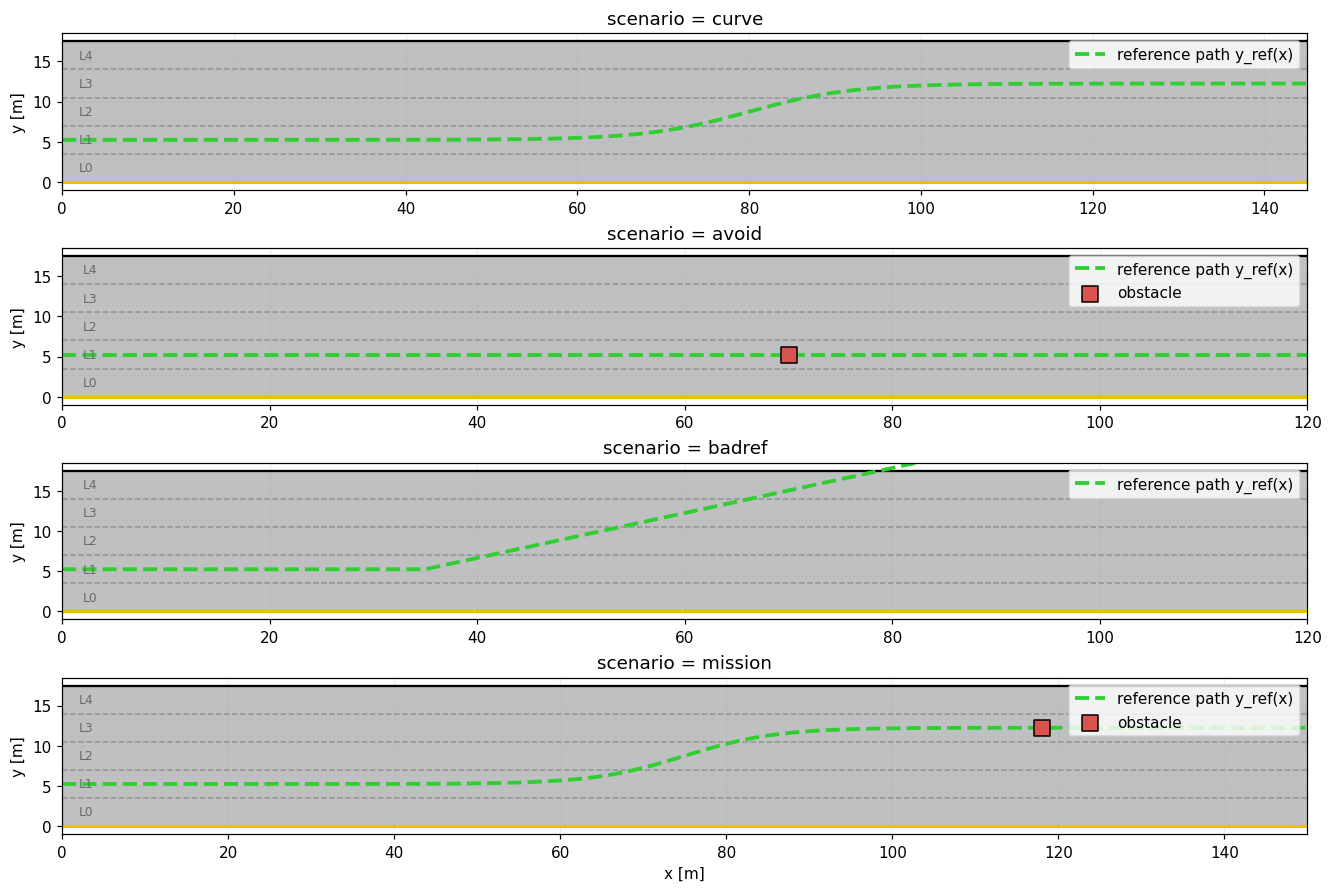

In [6]:
# [Theory 1] reference path + scenario -----------------------------------
def lane_change_reference(y_start, y_end, center_x, width):
    def yref(x):
        transition = 0.5 * (1.0 + np.tanh((x - center_x) / width))
        return y_start + (y_end - y_start) * transition

    def dyref(x):
        tanh_value = np.tanh((x - center_x) / width)
        transition_slope = 0.5 / width * (1.0 - tanh_value**2)
        return (y_end - y_start) * transition_slope

    return yref, dyref


def straight_reference(lane_id):
    lane_center = LANE[lane_id]

    def yref(x):
        return lane_center * np.ones_like(x)

    def dyref(x):
        return np.zeros_like(x)

    return yref, dyref


def bad_reference():
    def yref(x):
        return LANE[1] + 0.28 * np.clip(x - 35.0, 0.0, None)

    def dyref(x):
        return 0.28 * (x > 35.0).astype(float)

    return yref, dyref


# 시나리오 4가지 생성 
def make_scenario(name):
    # 1) curve  : 장애물 없이 L1 -> L3 로 부드럽게 차선변경 시나리오
    # 목적: reference 추종 
    if name == 'curve':
        yref, dyref = lane_change_reference(y_start=LANE[1], y_end=LANE[3], center_x=80.0, width=12.0)
        obstacles = []
        x_view = 145.0
        return yref, dyref, obstacles, x_view

    # 2) avoid  : L1 직진 reference + 같은 차선 앞 정지차 시나리오
    # 목적: 직진 중 장애물 회피
    if name == 'avoid':
        yref, dyref = straight_reference(lane_id=1)
        obstacles = [(70.0, LANE[1])]
        x_view = 120.0
        return yref, dyref, obstacles, x_view

    # 3) badref : reference 자체가 도로 밖을 향하는 시나리오 
    # 목적: hard constraint 보호 확인
    if name == 'badref':
        yref, dyref = bad_reference()
        obstacles = []
        x_view = 120.0
        return yref, dyref, obstacles, x_view

    # 4) mission: L1 -> L3 차선변경 + L3 앞 정지차 시나리오
    # 목적: 추종 + 회피 + 안전 종합 미션
    if name == 'mission':
        yref, dyref = lane_change_reference(y_start=LANE[1], y_end=LANE[3], center_x=75.0, width=11.0)
        obstacles = [(118.0, LANE[3])]
        x_view = 150.0
        return yref, dyref, obstacles, x_view

    raise ValueError(f'unknown scenario: {name}')


def thetaref(dyref, x):
    return np.arctan(dyref(x))


print('Theory 1 loaded: reference path + scenarios')


# [Theory 1 Preview] generated reference paths ---------------------------
def plot_reference_path_preview(scenario_names=None):
    if scenario_names is None:
        scenario_names = ['curve', 'avoid', 'badref', 'mission']

    fig, axes = plt.subplots(len(scenario_names), 1, figsize=(12, 8), constrained_layout=True)

    if len(scenario_names) == 1:
        axes = [axes]

    for ax, scenario_name in zip(axes, scenario_names):
        yref, dyref, obstacles, x_view = make_scenario(scenario_name)
        x_values = np.linspace(0.0, x_view, 500)
        y_values = yref(x_values)

        ax.axhspan(ROAD_Y0, ROAD_Y1, facecolor='#454b52', alpha=0.35)
        ax.plot([0.0, x_view], [ROAD_Y0, ROAD_Y0], color='#e8c100', lw=2)
        ax.plot([0.0, x_view], [ROAD_Y1, ROAD_Y1], color='black', lw=1.5)

        for lane_index in range(1, NUM_LANES):
            lane_y = lane_index * LANE_W
            ax.plot([0.0, x_view], [lane_y, lane_y], color='gray', lw=1.0, ls='--', alpha=0.7)

        for lane_index, lane_center in enumerate(LANE):
            ax.text(2.0, lane_center, f'L{lane_index}', va='center', fontsize=8, color='dimgray')

        ax.plot(x_values, y_values, '--', color='limegreen', lw=2.5, label='reference path y_ref(x)')

        for obstacle_x, obstacle_y in obstacles:
            ax.scatter(obstacle_x, obstacle_y, s=120, marker='s', color='#d9534f', edgecolor='black', zorder=5, label='obstacle')

        ax.set_title(f'scenario = {scenario_name}')
        ax.set_xlim(0.0, x_view)
        ax.set_ylim(ROAD_Y0 - 1.0, ROAD_Y1 + 1.0)
        ax.set_ylabel('y [m]')
        ax.grid(True, alpha=0.2)
        ax.legend(loc='upper right')

    axes[-1].set_xlabel('x [m]')
    plt.show()


plot_reference_path_preview()


## 2. Kinematic Bicycle Model (횡방향 / lateral)

### 왜 이렇게 두는가?
- 이번 실습은 **속도는 고정($V_{REF}$)** 하고 **횡방향(조향)만** 최적화한다.
- 그래서 **control input = 조향 변화율 $\dot\delta$** (핸들을 얼마나 빨리 돌릴지), **조향각 $\delta$ 는 state** 로 둔다.
- 실제 차량 LMPC 와 같은 구조다 (조향을 부드럽게 다루려고 $\delta$ 를 state, $\dot\delta$ 를 input 으로).

### State / Control
$$ \text{State}\quad \mathbf{x}=[\,x,\ y,\ \theta,\ \delta\,] \qquad\qquad \text{Control}\quad u=\dot\delta\ (\text{조향 변화율}) $$
( 속도 $v=V_{REF}$ 로 고정 )

### Model
$$
\begin{aligned}
\dot{x} &= v\cos\theta \\
\dot{y} &= v\sin\theta \\
\dot{\theta} &= \frac{v\tan\delta}{L} \\
\dot{\delta} &= u
\end{aligned}
$$

### Optimization 과의 연결

1. Solver가 control input $\dot\delta$ 를 선택한다

2. Bicycle model이 미래 trajectory(조향각 $\delta$ 포함)를 예측한다

3. Cost function이 reference path 와 비교한다

4. 가장 cost가 작은 $\dot\delta$ 시퀀스가 선택된다

> **실습**: 아래 코드 셀의 `____` 4곳을 채워 이 model 식을 완성하세요. 맞으면 **✅ 정답!** 이 뜨고, 그때부터 아래 모든 셀이 동작합니다.

In [ ]:
# [Theory 2] kinematic bicycle model (횡방향 / lateral) -------------------
# state   x = [x, y, θ, δ]   (위치, heading, 조향각)   * 속도 v 는 V_REF 로 고정
# control u = δ̇  (조향 변화율, steering rate)  ← solver 가 고르는 값(control input)
#
# TODO: 아래 4개의 ____ 를 채워 'Δt(dt) 동안 한 스텝 전진' 을 완성하세요.
#          규칙:  다음값 = 현재값 + (변화율) × dt
#          (속도 v = V_REF, 휠베이스 = L_WB, np.cos / np.sin / np.tan 사용)
def kinematic_bicycle_step(state, dsteer):
    x     = state[0]
    y     = state[1]
    theta = state[2]
    delta = state[3]                          # 조향각 (state)

    next_x     = ____ + ____ * ____                # TODO 1:  (hint)ẋ = v·cosθ        @@정답: x + V_REF * np.cos(theta) * dt
    next_y     = ____ + ____ * ____                # TODO 2:  (hint)ẏ = v·sinθ        @@정답: y + V_REF * np.sin(theta) * dt
    next_theta = ____ + ____ * ____                # TODO 3:  (hint)θ̇ = v·tanδ / L    @@정답: theta + V_REF * np.tan(delta) / L_WB * dt
    next_delta = ____ + ____ * ____                # TODO 4:  (hint)δ̇ = u             @@정답: delta + dsteer * dt

    return np.array([next_x, next_y, next_theta, next_delta])


def simulate(dsteer_sequence, initial_state):
    controls = np.asarray(dsteer_sequence).reshape(-1)   # δ̇ 시퀀스 (길이 N)
    states = np.zeros((len(controls) + 1, 4))
    states[0] = initial_state
    for step in range(len(controls)):
        states[step + 1] = kinematic_bicycle_step(states[step], controls[step])
    return states


def neutral_init(initial_state):
    return np.zeros(N)                        # 가장 단순한 초기 추정: δ̇ = 0 (직진)


def warm_start(initial_state, yref, dyref):
    # reference 를 대충 따라가는 비례 제어기로 초기 δ̇ 시퀀스를 만든다(solver warm start).
    state = np.array(initial_state, dtype=float)
    controls = np.zeros(N)
    for k in range(N):
        x, y, theta, delta = state
        theta_ref = np.arctan(dyref(x))
        lateral_error = float(yref(x)) - y
        delta_desired = (theta_ref - theta) + np.arctan2(0.5 * lateral_error, V_REF)
        delta_desired = np.clip(delta_desired, -MAX_STEER, MAX_STEER)
        dsteer = np.clip((delta_desired - delta) / dt, -MAX_DSTEER, MAX_DSTEER)
        controls[k] = dsteer
        state = kinematic_bicycle_step(state, dsteer)
    return controls


# TODO 를 채우고 이 셀을 실행하면 바로 결과가 표시됩니다.
try:
    _s0 = np.array([1.0, 2.0, 0.3, 0.10])                 # x=1, y=2, θ=0.3, δ=0.10
    _got = kinematic_bicycle_step(_s0, dsteer=0.05)
    _ans = np.array([1.0 + V_REF*np.cos(0.3)*dt,
                     2.0 + V_REF*np.sin(0.3)*dt,
                     0.3 + V_REF*np.tan(0.10)/L_WB*dt,
                     0.10 + 0.05*dt])
    if np.allclose(_got, _ans):
        print('✅ 정답! bicycle model 완성 — 이제 아래 모든 셀이 정상 동작합니다.')
    else:
        print('   아직 안 맞아요.')
        print('   내 결과:', np.round(_got, 4))
        print('   정답   :', np.round(_ans, 4))
except Exception as e:
    print('!!! 아직 ____ 빈칸이 남아 있어요 →', e)

⛔ 아직 ____ 빈칸이 남아 있어요 → name '____' is not defined


## 3. Cost Function — 무엇을 좋은 trajectory라고 볼 것인가 (횡방향)

### control input
- **control input** = $\dot\delta$ (조향 변화율) — solver 가 매 시점 고르는 값
- **조향각 $\delta$ 는 state** (현재 핸들 각도)

### 비용 항 (cost terms)

| 코드 weight | 코드 항 | 의미 |
|---|---|---|
| `track` | $\overline{(y-y_{ref})^2}$ | reference 에서 옆으로(y) 벗어남 |
| `heading` | $\overline{(\theta-\theta_{ref})^2}$ | 경로 방향과 어긋남 |
| `STEER_WEIGHT` (고정) | $\overline{\delta^2}$ | 조향각(state)을 불필요하게 크게 유지하지 않도록 |
| `comfort` | $\overline{\dot\delta^2}$ | **control input(조향 변화율)** 을 작게 = 부드러운 조향 |

전체 비용:
$$ J = w_{track}\overline{(y-y_{ref})^2} + w_{heading}\overline{(\theta-\theta_{ref})^2} + w_{steer}\overline{\delta^2} + w_{comfort}\overline{\dot\delta^2} $$

> 🔗 실제 LMPC 대응: $w_{track},w_{heading},w_{steer}$ = **Q**(상태 추종/정규화), $w_{comfort}$ = **R**(입력 $\dot\delta$ 벌점).

> **cost는 soft(선호)** : 장애물이 reference 위에 있으면 추종을 조금 손해 보더라도 **충돌 constraint를 우선**한다.
> 튜닝 초점 = **track · heading · comfort** ( `STEER_WEIGHT` 는 고정 ).

> **실습**: 아래 코드 셀의 `____` 4곳(각 비용 항)을 채우세요. 맞으면 **✅ 정답!** 이 뜹니다.

In [ ]:
# [Theory 3] cost function (횡방향) --------------------------------------
# 실제 LMPC 와 같은 구조:
#   tracking : (y - y_ref)²,  (θ - θ_ref)²          ← reference path 추종
#   조향각   : δ²   (state 정규화 — 핸들을 불필요하게 크게 유지하지 않도록)
#   조향변화 : δ̇²  (control input = 부드러운 조향 = comfort)
#
# TODO: 각 비용 항을 '평균 제곱(mean square)' 으로 완성하세요.                          (hint) np.mean( ___ ** 2 ))

def tracking_cost(states, yref):
    y_error = states[:, 1] - yref(states[:, 0])   # 횡방향(y) 오차
    return ____  # TODO 1: y_error 의 평균 제곱                                    @@정답: np.mean(y_error ** 2)

def heading_cost(states, dyref):
    theta_error = states[:, 2] - thetaref(dyref, states[:, 0])   # heading 오차
    return ____  # TODO 2: theta_error 의 평균 제곱                                @@정답: np.mean(theta_error ** 2)

def steer_cost(states):
    return ____  # TODO 3: 조향각 δ(=states[:,3]) 의 평균 제곱                      @@정답: np.mean(states[:, 3] ** 2)

def comfort_cost(controls):
    controls = np.asarray(controls)               # control input δ̇
    return ____  # TODO 4: δ̇(=controls) 의 평균 제곱                               @@정답: np.mean(controls ** 2)

def cost_terms_from_controls(z, yref, dyref, initial_state):
    controls = np.asarray(z).reshape(-1)                 # δ̇ 시퀀스
    states = simulate(controls, initial_state)
    terms = {
        'track':   tracking_cost(states, yref),          # (y - y_ref)²
        'heading': heading_cost(states, dyref),          # (θ - θ_ref)²
        'steer':   steer_cost(states),                   # δ²  (조향각 크기)
        'comfort': comfort_cost(controls),               # δ̇² (조향 변화율 = control input)
    }
    return terms, states, controls

def cost_fn(z, weights, yref, dyref, initial_state):
    terms, _, _ = cost_terms_from_controls(z, yref, dyref, initial_state)
    return (
        weights['track']   * terms['track']
        + weights['heading'] * terms['heading']
        + STEER_WEIGHT       * terms['steer']            # 고정 weight (δ²)
        + weights['comfort'] * terms['comfort']          # δ̇²
    )

# TODO 를 채우고 이 셀을 실행하면 바로 결과가 표시됩니다.
try:
    _s = np.array([[0., 0.0, 0.00, 0.10],
                   [1., 0.5, 0.05, 0.20],
                   [2., 1.0, 0.10, 0.15]])               # 예시 states [x, y, θ, δ]
    _z = np.array([0.5, -0.25])                          # 예시 control δ̇
    _yr  = lambda x: 0.5 * np.ones_like(x)
    _dyr = lambda x: np.zeros_like(x)
    _ans = {'track':   np.mean((_s[:, 1] - _yr(_s[:, 0]))**2),
            'heading': np.mean((_s[:, 2] - thetaref(_dyr, _s[:, 0]))**2),
            'steer':   np.mean(_s[:, 3]**2),
            'comfort': np.mean(_z**2)}
    _mine = {'track': tracking_cost(_s, _yr), 'heading': heading_cost(_s, _dyr),
             'steer': steer_cost(_s), 'comfort': comfort_cost(_z)}
    if all(np.isclose(_mine[k], _ans[k]) for k in _ans):
        print('✅ 정답! cost function 완성 — 이제 아래 모든 셀이 정상 동작합니다.')
    else:
        print(' 아직 안 맞아요:')
        for k in _ans:
            print('   [%s] %-8s 내 결과=%.5f / 정답=%.5f'
                  % ('OK' if np.isclose(_mine[k], _ans[k]) else 'X', k, _mine[k], _ans[k]))
except Exception as e:
    print('!!! 아직 ____ 빈칸이 남아 있어요 →', e)

Theory 3 loaded: lateral cost  (track + heading + δ² + δ̇²)


## 4. Hard Constraints — 절대 어기면 안 되는 조건

- **왜 cost로는 부족한가?**
  - 안전을 전부 cost(벌점)에 맡기면, solver가 *"조금 부딪혀도 다른 cost가 낮으니 OK"* 라는 해를 고를 수 있음
  - 그래서 안전은 **hard constraint로 분리**

**① 충돌 회피**
- ego·장애물을 **여러 개의 원**으로 근사 → 모든 시간 step에서 원 사이 거리 ≥ 안전거리
$$ d_{collision}=d-(r_{ego}+r_{obj})-d_{safe}\ge 0 $$
- $d$ = ego 원과 장애물 원 중심 거리 / 0보다 작아지면 **너무 가까움 → 금지**

**② 도로 경계**
- 차량 대표점이 도로 아래·위 경계 안에 있어야 함
$$ y_{ego}-y_{road,min}\ge0,\qquad y_{road,max}-y_{ego}\ge0 $$

**③ Control bound**
- 가속도·조향각은 물리적으로 가능한 범위 안 (각각 상·하한)

> **핵심**
> - **Soft (양보 가능)** : reference 추종, comfort
> - **Hard (양보 불가)** : 충돌, 도로 이탈, 제어 한계
>
> 이 구분이 optimization trajectory planning의 핵심입니다.

> **실습**: 아래 코드 셀의 `____` 4곳(충돌 회피·도로 경계)을 채우세요. 맞으면 **✅ 정답!** 이 뜹니다.

In [ ]:
# [Theory 4] hard constraints --------------------------------------------
# 충돌 회피 / 도로 경계는 'soft cost' 가 아니라 '반드시 지켜야 하는 hard 제약'.
# SciPy SLSQP 의 ineq 제약 규칙:  fun(z) >= 0  이면 만족.
#   → 모든 제약 값을 '여유(margin) >= 0' 형태로 만든다.
#
# TODO: 충돌 회피(TODO 1~2) 와 도로 경계(TODO 3~4) 식을 완성하세요.
def obstacle_circle_centers(obstacles):
    centers = []
    for obstacle_x, obstacle_y in obstacles:
        for offset_x in [-1.5, 0.0, 1.5]:                # 앞 / 중앙 / 뒤
            centers.append((obstacle_x + offset_x, obstacle_y))
    return centers

def ego_circle_centers(states):
    centers = []
    for offset in EGO_OFFSETS:
        x_center = states[:, 0] + offset * np.cos(states[:, 2])
        y_center = states[:, 1] + offset * np.sin(states[:, 2])
        centers.append(np.stack([x_center, y_center], axis=1))
    return centers

_obs_circles = obstacle_circle_centers
_ego_pts = ego_circle_centers

# (제약 1) 충돌 회피: 모든 (ego원 × 장애물원 × 시점) 에서  '중심거리 - 최소허용거리 >= 0'
def collision_constraint_values(states, obstacles):
    if not obstacles:
        return np.array([1.0])
    constraint_values = []
    minimum_allowed_distance = R_EGO + R_OBJ + D_SAFE       # ego반지름 + 장애물반지름 + 안전여유
    for ego_centers in ego_circle_centers(states):
        for obstacle_x, obstacle_y in obstacle_circle_centers(obstacles):
            dx = ego_centers[:, 0] - obstacle_x
            dy = ego_centers[:, 1] - obstacle_y
            distance = ____                                # TODO 1: (hint) 두 원 중심거리 = √(dx² + dy²)      @@정답: np.sqrt(dx**2 + dy**2)
            constraint_values.append(____)                 # TODO 2: (hint) 여유 = 중심거리 − 최소허용거리        @@정답: distance - minimum_allowed_distance
    return np.concatenate(constraint_values)

# (제약 2) 도로 경계: ego 대표점의 y 가 도로 안에  ->  '아래 여유 >= 0' 그리고 '위 여유 >= 0'
def road_boundary_constraint_values(states):
    constraint_values = []
    road_lower_limit = ROAD_Y0 + ROAD_MARGIN
    road_upper_limit = ROAD_Y1 - ROAD_MARGIN
    for ego_centers in ego_circle_centers(states):
        ego_y = ego_centers[:, 1]
        constraint_values.append(____)                     # TODO 3: 아래 경계 여유 = ego_y − 아래한계          @@정답: ego_y - road_lower_limit
        constraint_values.append(____)                     # TODO 4: 위  경계 여유 = 위한계 − ego_y            @@정답: road_upper_limit - ego_y
    return np.concatenate(constraint_values)

# (제약 3) 조향각 한계: |δ| <= MAX_STEER   (state bound, 항상 적용) — 이미 완성됨
def steer_limit_constraint_values(states):
    delta = states[:, 3]
    return np.concatenate([MAX_STEER - delta, MAX_STEER + delta])

def cons_fn(z, obstacles, initial_state, use_collision, use_road):
    states = simulate(z, initial_state)                  # control(δ̇) -> trajectory
    constraints = [steer_limit_constraint_values(states)]   # 조향각 한계(항상)
    if use_collision:
        constraints.append(collision_constraint_values(states, obstacles))
    if use_road:
        constraints.append(road_boundary_constraint_values(states))
    return np.concatenate(constraints)

# TODO 를 채우고 이 셀을 실행하면 바로 결과가 표시됩니다.
try:
    _st  = np.array([[20., 4.0, 0.0, 0.0],
                     [21., 4.2, 0.0, 0.0]])               # 예시 trajectory [x, y, θ, δ]
    _obs = [(25., 6.0)]
    # --- 정답(reference) 직접 계산 ---
    _min_d = R_EGO + R_OBJ + D_SAFE
    _col_ref = []
    for _ec in ego_circle_centers(_st):
        for _ox, _oy in obstacle_circle_centers(_obs):
            _d = np.sqrt((_ec[:, 0] - _ox)**2 + (_ec[:, 1] - _oy)**2)
            _col_ref.append(_d - _min_d)
    _col_ref = np.concatenate(_col_ref)
    _lo, _hi = ROAD_Y0 + ROAD_MARGIN, ROAD_Y1 - ROAD_MARGIN
    _road_ref = []
    for _ec in ego_circle_centers(_st):
        _road_ref.append(_ec[:, 1] - _lo); _road_ref.append(_hi - _ec[:, 1])
    _road_ref = np.concatenate(_road_ref)
    # --- 학생 함수 결과 ---
    _col  = collision_constraint_values(_st, _obs)
    _road = road_boundary_constraint_values(_st)
    _ok_c = np.allclose(_col,  _col_ref)
    _ok_r = np.allclose(_road, _road_ref)
    if _ok_c and _ok_r:
        print('✅ 정답! 제약(충돌·도로) 완성 — 이제 아래 모든 셀이 정상 동작합니다.')
    else:
        print(' 아직 안 맞아요:  [%s] 충돌 회피   [%s] 도로 경계'
              % ('OK' if _ok_c else 'X', 'OK' if _ok_r else 'X'))
except Exception as e:
    print('!!! 아직 ____ 빈칸이 남아 있어요 →', e)

Theory 4 loaded: hard constraints  (|δ|≤MAX, collision, road)


## 5. Solver — 비용과 제약을 풀어 최적 control 찾기

- **여러 control input(조향 변화율) 조합을 자동으로 바꿔 가며, cost 가 가장 작고 제약을 만족하는 조합을 찾아주는 도구**
- 우리가 weight 를 정하면, solver 는 그 weight 아래 *최적의 조향* 을 대신 찾아 준다.
- 이번 실습은 **SciPy 의 `SLSQP`** solver 를 사용한다.

In [10]:
# [Theory 5] solver wrapper ----------------------------------------------
def solve_trajectory_optimization(weights, scenario, use_collision=True, use_road=True):
    yref, dyref, obstacles, x_view = make_scenario(scenario)
    initial_state = np.array([12.0, LANE[1], 0.0, 0.0])   # x, y, θ, δ(=0, 직진)
    initial_guess = warm_start(initial_state, yref, dyref)  # reference 추종 초기 추정

    bounds = [(-MAX_DSTEER, MAX_DSTEER)] * N              # control input(δ̇) 한계
    constraints = [{
        'type': 'ineq',
        'fun': lambda z: cons_fn(z, obstacles, initial_state, use_collision, use_road),
    }]

    result = minimize(
        fun=lambda z: cost_fn(z, weights, yref, dyref, initial_state),
        x0=initial_guess,
        method='SLSQP',
        bounds=bounds,
        constraints=constraints,
        options={'maxiter': 400, 'ftol': 1e-7},
    )

    context = {'yref': yref, 'dyref': dyref, 'obs': obstacles, 'xview': x_view,
               'x0': initial_state, 'use_collision': use_collision,
               'use_road': use_road, 'W': weights}
    return result, context


def optimize(weights, scenario, use_collision=True, use_road=True):
    result, context = solve_trajectory_optimization(weights, scenario, use_collision, use_road)
    terms, states, controls = cost_terms_from_controls(
        result.x, context['yref'], context['dyref'], context['x0'])
    return {'s': states, 'u': controls, 'yref': context['yref'], 'dyref': context['dyref'],
            'obs': context['obs'], 'xview': context['xview'], 'scenario': scenario,
            'W': weights, 'cost_terms': terms, 'objective': result.fun,
            'solver_success': result.success, 'solver_message': result.message,
            'use_collision': use_collision, 'use_road': use_road}

print('Theory 5 loaded: SLSQP solver wrapper (warm-started)')

Theory 5 loaded: SLSQP solver wrapper (warm-started)


/tmp/ipykernel_3192104/2955346295.py:17: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from current font.
  plt.legend(loc='upper left', fontsize=8); plt.tight_layout(); plt.show()
/tmp/ipykernel_3192104/2955346295.py:17: UserWarning: Glyph 54396 (\N{HANGUL SYLLABLE PUN}) missing from current font.
  plt.legend(loc='upper left', fontsize=8); plt.tight_layout(); plt.show()
/tmp/ipykernel_3192104/2955346295.py:17: UserWarning: Glyph 54945 (\N{HANGUL SYLLABLE HOENG}) missing from current font.
  plt.legend(loc='upper left', fontsize=8); plt.tight_layout(); plt.show()
/tmp/ipykernel_3192104/2955346295.py:17: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from current font.
  plt.legend(loc='upper left', fontsize=8); plt.tight_layout(); plt.show()
/tmp/ipykernel_3192104/2955346295.py:17: UserWarning: Glyph 54693 (\N{HANGUL SYLLABLE HYANG}) missing from current font.
  plt.legend(loc='upper left', fontsize=8); plt.tight_layout(); plt.show()
/tmp/ipykernel_3192104/295

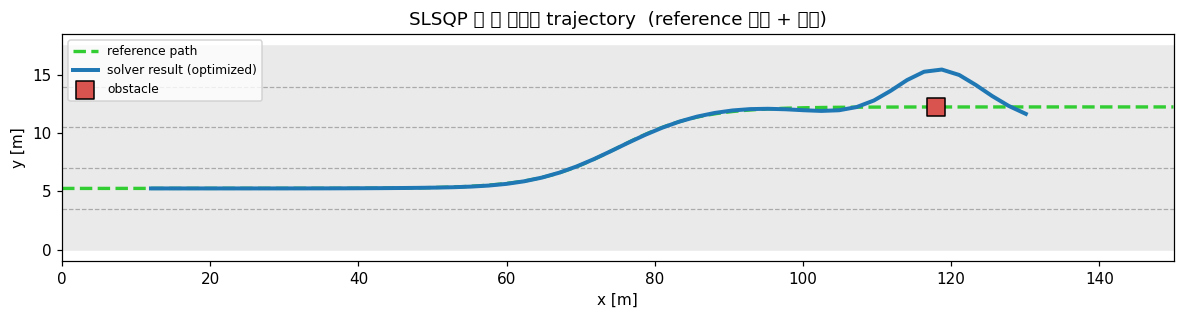

In [ ]:
# --- solver 가 실제로 푼 결과 (예시: mission) ---
_demo = optimize(weights={'track': 10, 'heading': 10, 'comfort': 20}, scenario='mission')
_s, _xv = _demo['s'], _demo['xview']
_xx = np.linspace(0.0, _xv, 400)

plt.figure(figsize=(11, 3.0))
plt.axhspan(ROAD_Y0, ROAD_Y1, color='#eaeaea')
for _li in range(1, NUM_LANES):
    plt.plot([0, _xv], [_li * LANE_W] * 2, color='gray', ls='--', lw=0.8, alpha=0.6)
plt.plot(_xx, _demo['yref'](_xx), '--', color='limegreen', lw=2.2, label='reference path')
plt.plot(_s[:, 0], _s[:, 1], color='#1f77b4', lw=2.6, label='solver result (optimized)')
for _ox, _oy in _demo['obs']:
    plt.scatter(_ox, _oy, s=150, marker='s', color='#d9534f', edgecolor='black', zorder=5, label='obstacle')
plt.xlim(0, _xv); plt.ylim(ROAD_Y0 - 1, ROAD_Y1 + 1)
plt.xlabel('x [m]'); plt.ylabel('y [m]')
plt.title('SLSQP - trajectory')
plt.legend(loc='upper left', fontsize=8); plt.tight_layout(); plt.show()

---
# 시연 때 사용할 시각화 코드 — 해당 셀 들은 단순 실행

아래부터는 최적화 문제를 정의하는 코드가 아니라, 결과를 보기 좋게 보여주기 위한 코드입니다.
수업 중 이론을 따라갈 때는 위의 `Theory 0~5` 를 중심으로 보면 됩니다.

In [12]:
# [Visualization 1] road and vehicle drawing -----------------------------
class Car:
    def __init__(
        self,
        x,
        y,
        theta=0.0,
        color='#8a8f96',
        length=4.6,
        width=2.0,
        name='car',
    ):
        self.x = x
        self.y = y
        self.theta = theta
        self.color = color
        self.length = length
        self.width = width
        self.name = name

    def circles(self, n=3):
        offsets = np.linspace(0.6, self.length - 0.6, n)
        x_centers = self.x + offsets * np.cos(self.theta)
        y_centers = self.y + offsets * np.sin(self.theta)

        return np.stack([x_centers, y_centers], axis=1)

    @property
    def radius(self):
        return self.width / 2.0 + 0.1


def draw_road(ax, x_view=(0.0, ROAD_LEN), ids=True):
    x_min = x_view[0]
    x_max = x_view[1]

    ax.set_facecolor('#2f343a')
    ax.add_patch(
        Rectangle(
            (x_min, ROAD_Y0),
            x_max - x_min,
            ROAD_Y1,
            facecolor='#454b52',
            zorder=0,
        )
    )
    ax.plot([x_min, x_max], [ROAD_Y0, ROAD_Y0], color='#e8c100', lw=3, zorder=1)
    ax.plot([x_min, x_max], [ROAD_Y1, ROAD_Y1], color='white', lw=3, zorder=1)

    for lane_id in range(1, NUM_LANES):
        lane_y = lane_id * LANE_W
        ax.plot(
            [x_min, x_max],
            [lane_y, lane_y],
            color='white',
            lw=1.5,
            ls=(0, (14, 12)),
            alpha=0.9,
            zorder=1,
        )

    if ids:
        for lane_id, lane_center in enumerate(LANE):
            ax.text(
                x_min + 2.0,
                lane_center,
                f'L{lane_id}',
                color='white',
                fontsize=8,
                va='center',
                alpha=0.5,
            )
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(ROAD_Y0 - 1.5, ROAD_Y1 + 1.5)
    ax.set_aspect('equal')
    ax.set_xlabel('x [m]')
    ax.set_ylabel('y [m]')

def draw_car(ax, car, steer=0.0, alpha=0.95, circles=False):
    transform = mtransforms.Affine2D().rotate_around(
        car.x,
        car.y,
        car.theta,
    ) + ax.transData

    body = FancyBboxPatch(
        (car.x, car.y - car.width / 2.0),
        car.length,
        car.width,
        boxstyle='round,pad=0.02,rounding_size=0.5',
        lw=1.1,
        edgecolor='black',
        facecolor=car.color,
        alpha=alpha,
        transform=transform,
        zorder=5,
    )
    ax.add_patch(body)

    cabin = Rectangle(
        (car.x + car.length * 0.58, car.y - car.width * 0.32),
        car.length * 0.2,
        car.width * 0.64,
        facecolor='#bfe3ff',
        edgecolor='none',
        alpha=0.85,
        transform=transform,
        zorder=6,
    )
    ax.add_patch(cabin)

    wheel_specs = [
        (car.x, car.y - car.width / 2.0, False),
        (car.x, car.y + car.width / 2.0, False),
        (car.x + L_WB, car.y - car.width / 2.0, True),
        (car.x + L_WB, car.y + car.width / 2.0, True),
    ]

    for wheel_x, wheel_y, is_front_wheel in wheel_specs:
        wheel_transform = transform

        if is_front_wheel and abs(steer) > 1e-6:
            wheel_transform = (
                mtransforms.Affine2D().rotate_around(wheel_x, wheel_y, steer)
                .rotate_around(car.x, car.y, car.theta)
                + ax.transData
            )

        wheel = Rectangle(
            (wheel_x - 0.37, wheel_y - 0.14),
            0.75,
            0.28,
            facecolor='#111111',
            transform=wheel_transform,
            zorder=7,
        )
        ax.add_patch(wheel)

    if car.name == 'ego':
        ax.add_patch(Circle((car.x, car.y), 0.18, color='red', zorder=8))

    if circles:
        for center_x, center_y in car.circles():
            ax.add_patch(
                Circle(
                    (center_x, center_y),
                    car.radius,
                    fill=False,
                    edgecolor='red',
                    ls=':',
                    lw=1,
                    zorder=8,
                )
            )

print('Visualization 1 loaded: road + vehicle drawing')

Visualization 1 loaded: road + vehicle drawing


In [13]:
# [Visualization 2] scorecard + run wrapper ------------------------------
def evaluate(res):
    states = res['s']
    controls = res['u']           # δ̇ 시퀀스 (control input)
    yref = res['yref']
    obstacles = res['obs']

    tracking_mask = np.ones(len(states), dtype=bool)
    for obstacle_x, _ in obstacles:
        tracking_mask = tracking_mask & (np.abs(states[:, 0] - obstacle_x) > 12.0)
    tracking_error = states[tracking_mask, 1] - yref(states[tracking_mask, 0])
    tracking_rmse = np.sqrt(np.mean(tracking_error**2))

    road_violation = max(
        0.0,
        (ROAD_Y0 + ROAD_MARGIN) - states[:, 1].min(),
        states[:, 1].max() - (ROAD_Y1 - ROAD_MARGIN),
    )

    if obstacles:
        clearances = []
        for ego_centers in ego_circle_centers(states):
            for obstacle_x, obstacle_y in obstacle_circle_centers(obstacles):
                dx = ego_centers[:, 0] - obstacle_x
                dy = ego_centers[:, 1] - obstacle_y
                distance = np.sqrt(dx**2 + dy**2)
                clearances.append(distance.min() - (R_EGO + R_OBJ))
        minimum_clearance = min(clearances)
    else:
        minimum_clearance = 99.0

    # comfort = 조향 변화율 |δ̇| (control input) 의 최댓값
    steering_rate = np.max(np.abs(controls)) if len(controls) else 0.0

    return {
        'Tracking': (
            tracking_rmse < 1.0,
            f'RMSE={tracking_rmse:.2f} m',
        ),
        'On-road': (
            road_violation < 0.05,
            f'out={road_violation:.2f} m',
        ),
        'No-collision': (
            (minimum_clearance > -0.05) if obstacles else True,
            f'clear={minimum_clearance:+.2f} m' if obstacles else 'no obstacle',
        ),
        'Comfort': (
            steering_rate < COMFORT_DSTEER,
            f'max|dsteer|={steering_rate:.2f} rad/s',
        ),
    }


def visualize_plan(res, title=None, snap=6):
    states = res['s']
    yref = res['yref']
    obstacles = res['obs']
    x_view = res['xview']

    checks = evaluate(res)
    num_passed = sum(passed for passed, _ in checks.values())
    passed_all = num_passed == 4

    fig = plt.figure(figsize=(15, 5.4))
    grid = fig.add_gridspec(2, 1, height_ratios=[4, 1.0], hspace=0.45)
    ax = fig.add_subplot(grid[0])
    score_ax = fig.add_subplot(grid[1])
    score_ax.axis('off')

    draw_road(ax, x_view=(0.0, x_view))

    reference_x = np.linspace(0.0, x_view, 400)
    ax.plot(reference_x, yref(reference_x), '--', color='lime', lw=2.2,
            zorder=2, label='reference path (goal)')

    for obstacle_x, obstacle_y in obstacles:
        obstacle_car = Car(x=obstacle_x - 2.3, y=obstacle_y, theta=0.0,
                           color='#d9534f', name='obs')
        draw_car(ax, obstacle_car, circles=True)

    ax.plot(states[:, 0], states[:, 1], color='cyan', lw=2.4, zorder=3,
            label='planned trajectory (result)')

    for step in range(0, len(states), snap):
        ego_car = Car(x=states[step, 0], y=states[step, 1], theta=states[step, 2],
                      color='#1f77b4', name='ego')
        draw_car(ax=ax, car=ego_car, steer=states[step, 3], alpha=0.9)   # δ = state[3]

    ax.legend(loc='upper left', fontsize=9)

    banner = 'MISSION COMPLETE' if passed_all else 'MISSION FAILED'
    banner = f'{banner}  ({num_passed}/4)'
    if title:
        banner = f'{title}   —   {banner}'
    ax.set_title(banner, color=('#1a9850' if passed_all else '#d62728'),
                 fontsize=15, fontweight='bold')

    for index, (name, (is_ok, text)) in enumerate(checks.items()):
        box_x = index / 4.0 + 0.01
        score_ax.add_patch(Rectangle((box_x, 0.15), 0.23, 0.7,
                           transform=score_ax.transAxes,
                           facecolor=('#1a9850' if is_ok else '#d62728'), alpha=0.85))
        score_ax.text(box_x + 0.115, 0.62, f"{'✓' if is_ok else '✗'} {name}",
                      transform=score_ax.transAxes, ha='center', va='center',
                      color='white', fontsize=12, fontweight='bold')
        score_ax.text(box_x + 0.115, 0.33, text, transform=score_ax.transAxes,
                      ha='center', va='center', color='white', fontsize=9)

    plt.show()
    return checks


def run(W, scenario='mission', use_collision=True, use_road=True, title=None, snap=6):
    res = optimize(weights=W, scenario=scenario,
                   use_collision=use_collision, use_road=use_road)
    visualize_plan(res, title=title, snap=snap)
    return res


print('Visualization 2 loaded: scorecard + run')

Visualization 2 loaded: scorecard + run


In [14]:
# [Visualization 3] profiles + animation ---------------------------------
def show_profiles(res):
    states = res['s']
    controls = res['u']                              # δ̇ (control input)
    control_time = np.arange(len(controls)) * dt
    state_time = np.arange(len(states)) * dt

    fig, axes = plt.subplots(1, 3, figsize=(14, 2.6))

    axes[0].plot(control_time, np.degrees(controls))
    axes[0].set_title('control input δ̇  [deg/s]')

    axes[1].plot(state_time, np.degrees(states[:, 3]))
    axes[1].set_title('steering angle δ  [deg]')

    axes[2].plot(states[:, 0], states[:, 1], label='y')
    ref_x = states[:, 0]
    axes[2].plot(ref_x, res['yref'](ref_x), '--', color='gray', label='y_ref')
    axes[2].set_title('lateral y(x)'); axes[2].legend(fontsize=8)
    axes[2].set_xlabel('x [m]')

    for ax in (axes[0], axes[1]):
        ax.set_xlabel('t [s]')
    for ax in axes:
        ax.grid(True)

    plt.tight_layout()
    plt.show()


def animate(res, frame_step=2):
    states = res['s']
    obstacles = res['obs']
    yref = res['yref']

    fig, ax = plt.subplots(figsize=(11, 3.3))

    def update(frame_index):
        ax.clear()
        center_x = states[frame_index, 0]
        draw_road(ax, x_view=(center_x - 28.0, center_x + 40.0), ids=False)

        reference_x = np.linspace(center_x - 28.0, center_x + 40.0, 200)
        ax.plot(reference_x, yref(reference_x), '--', color='lime', lw=2)

        for obstacle_x, obstacle_y in obstacles:
            obstacle_car = Car(x=obstacle_x - 2.3, y=obstacle_y, theta=0.0,
                               color='#d9534f', name='obs')
            draw_car(ax, obstacle_car)

        ego_car = Car(x=states[frame_index, 0], y=states[frame_index, 1],
                      theta=states[frame_index, 2], color='#1f77b4', name='ego')
        draw_car(ax=ax, car=ego_car, steer=states[frame_index, 3])   # δ = state[3]

        ax.plot(states[:frame_index + 1, 0], states[:frame_index + 1, 1],
                color='cyan', lw=1.8)
        ax.set_title(f't={frame_index * dt:.1f}s   δ={np.degrees(states[frame_index, 3]):+.1f}°')

    animation = FuncAnimation(fig, update, frames=range(0, len(states), frame_step), interval=70)
    plt.close(fig)
    return HTML(animation.to_jshtml())

print('Visualization 3 loaded: profiles + animation')

Visualization 3 loaded: profiles + animation


---
# 강사 시연 전에 핵심 이론

전체 planning 흐름을 한 번에 다시 묶으면:

1. **Reference path를 받는다**
   - 목표이지만 절대 명령은 아님 → 안전하지 않으면 **잠시 포기** 할 수 있어야 함
2. **Vehicle model로 미래를 예측한다**
   - bicycle model 덕분에 solver의 trajectory가 최소한 *"차처럼 움직이는"* 형태가 됨
3. **Cost function으로 trajectory를 평가한다**
   - tracking(경로 이탈) + heading(방향 차이) + comfort(급조작) → weight로 우선순위 결정
4. **Hard constraint로 안전을 강제한다**
   - 충돌·도로 경계는 *"벌점 많은 항"* 이 아니라 *"절대 넘으면 안 되는 선"*

**강사 실습 시연 (실패 case)**

| 실패 case | 결과 |
|---|---|
| tracking weight 없음 | reference 무시하고 직진 |
| comfort weight 너무 작음 | 움직임이 거칠어짐 |
| collision constraint 끔 | 장애물을 뚫고 감 |
| road boundary constraint 끔 | 잘못된 reference 따라 도로 밖으로 |

> **수강생 실습의 목표**
> 숫자를 외우는 게 아니라 →
> **어떤 문제는 cost weight로 고치고, 어떤 문제는 hard constraint로 막아야 하는지** 를 구분하는 것

---
# 미션 살펴보기

`mission` 시나리오입니다. **초록 점선**(reference)은 L1→L3로 부드럽게 차선변경하는 경로이고,
그 끝 **L3에 빨간 정지차**가 있습니다. 좋은 planner라면: 초록선을 따라가다가, 빨간차 앞에서
살짝 비켜 안전거리를 확보하고, 부드럽게 — 즉 **결과 4개 모두 초록**이어야 합니다.

먼저 "잘 된 정답"이 어떤 모습인지 한 번 봅시다.

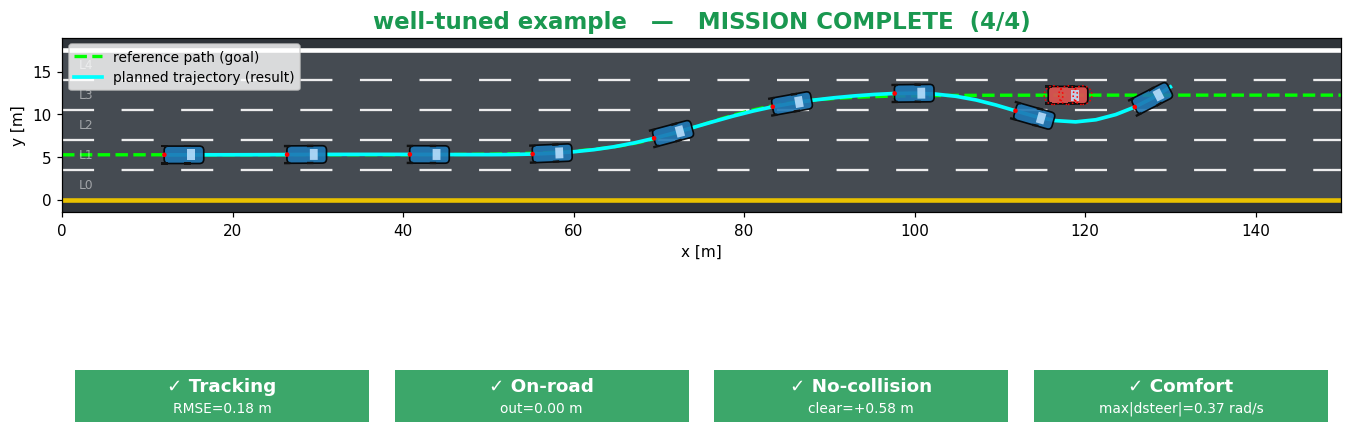

In [23]:
# 잘 튜닝된 weight 예시 (정답 중 하나)
W_good = {'track':10, 'heading':10, 'comfort':100}
res = run(W_good, scenario='mission', title='well-tuned example')

위처럼 파란 궤적이 초록선을 따라가다 빨간차를 살짝 돌아 피하면 성공입니다.
이게 어떻게 가능한지, 이제 **일부러 망가뜨려** 가며 각 weight의 역할을 봅니다.

---
# 실패 case (강사 시연)

각 셀은 비용 함수의 한 부분을 **잘못** 줍니다.

### 실패 ①  *"reference를 무시한다"* — track·heading weight ≈ 0
추종 벌점이 없으니 planner는 초록 곡선을 따라갈 이유가 없습니다. 그냥 직진해 버립니다.

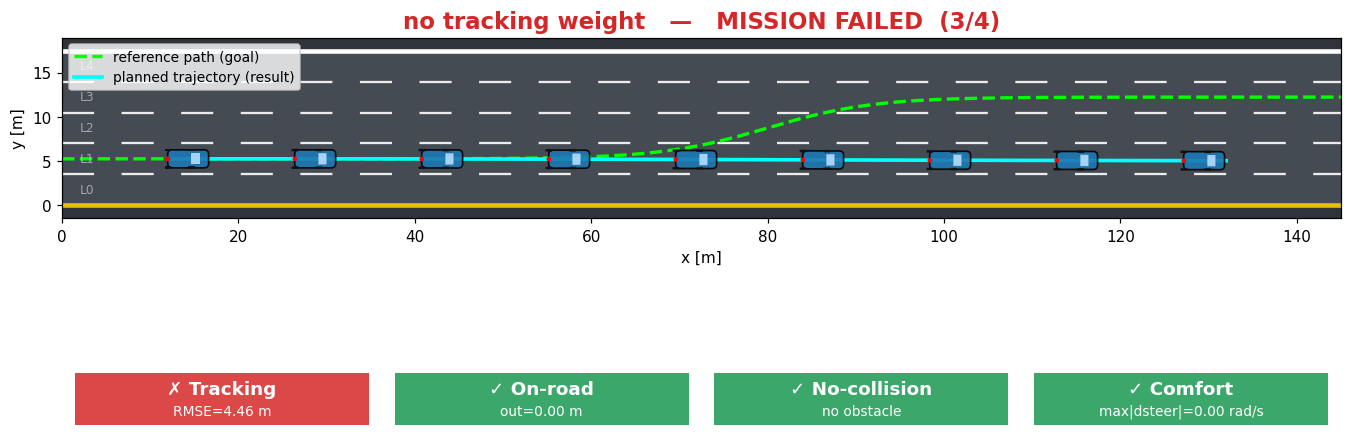

In [16]:
res = run({'track':0, 'heading':0, 'comfort':2}, scenario='curve', title='no tracking weight')

**중요**: `track`/`heading` 은 *"초록선을 따라가라"* 는 지시. 0이면 경로를 완전히 무시 → **Tracking ✗**.

### 실패 ②  *"휙휙 꺾는다"* — comfort weight 너무 작음
부드러움 벌점이 거의 없으니 핸들을 급하게(조향 변화율 $\dot\delta$ 가 큼) 휙휙 꺾어 조향이 톱니처럼 됩니다.

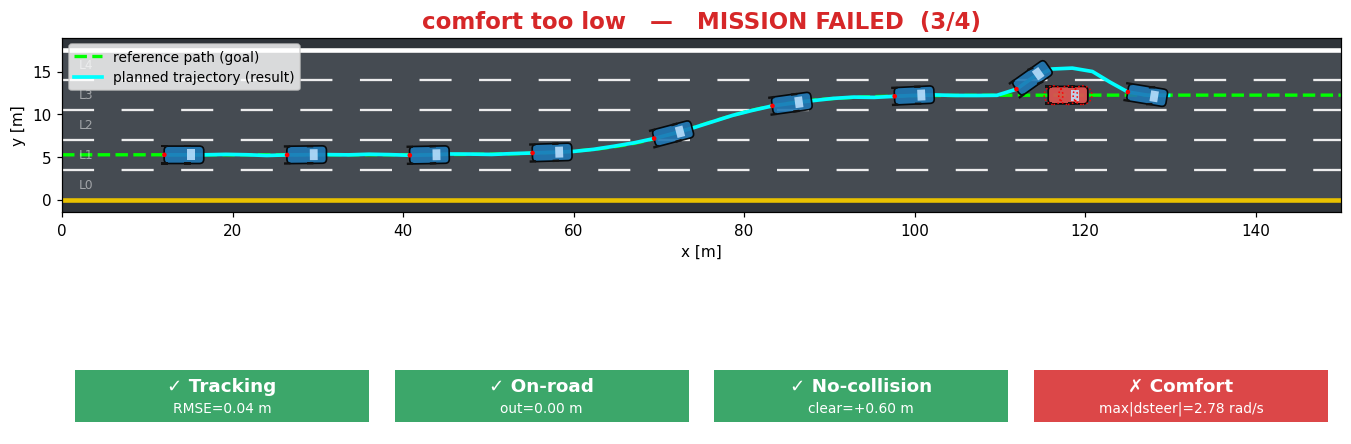

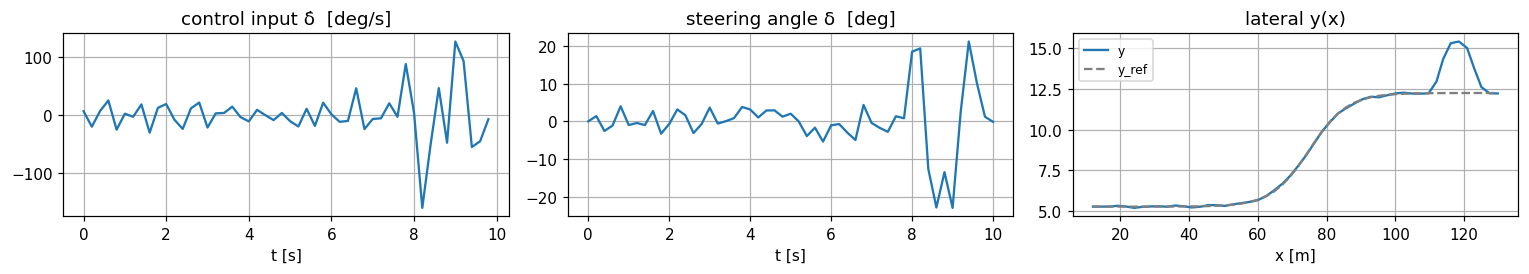

In [18]:
res = run({'track':10, 'heading':8, 'comfort':0.0}, scenario='mission', title='comfort too low')
show_profiles(res)

**중요**: `comfort` 가 너무 작으면 승차감이 끔찍해집니다 → **Comfort ✗** (조향 변화율 $|\dot\delta|$ 이 큼).

### 실패 ③  *"장애물을 뚫고 간다"* — 충돌 제약을 꺼버림
충돌은 **hard 제약**입니다. 이걸 끄면(`use_collision=False`) planner는 초록선을 충실히 따라
빨간차를 그대로 관통합니다.

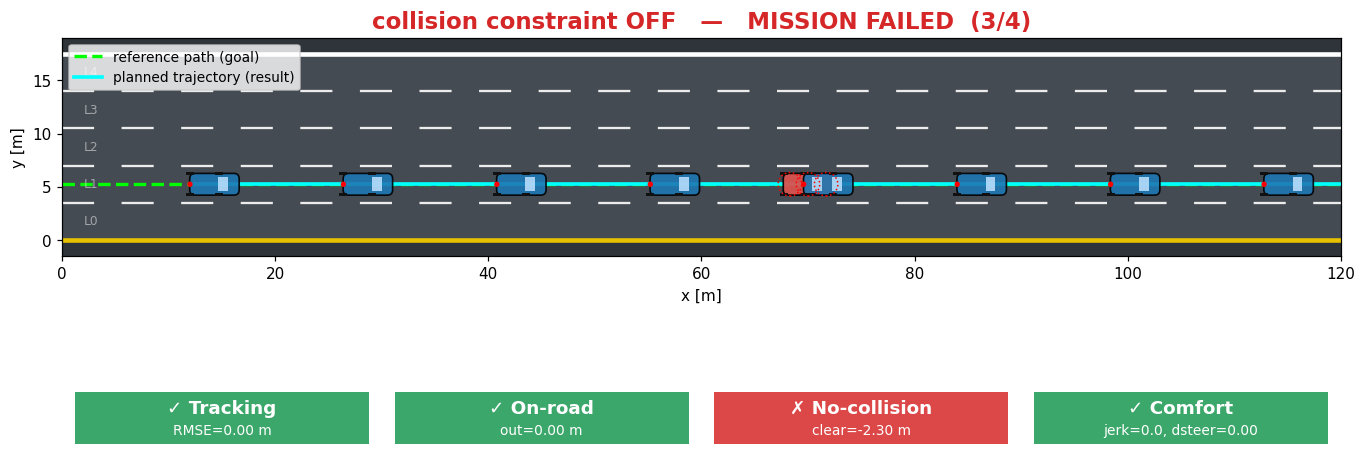

In [73]:
res = run({'track':8, 'heading':12, 'comfort':8}, scenario='avoid',
          use_collision=False, title='collision constraint OFF')

**중요**: 충돌 회피는 비용으로 부탁하는 게 아니라 **제약으로 금지**해야 안전합니다 → **No-collision ✗**.

### 실패 ④  *"나쁜 목표를 곧이곧대로 따라간다"* — reference가 도로 밖으로
`badref` 는 reference 자체가 도로 밖을 향합니다. 도로 경계 제약을 **끄면** 차는 초록선을 믿고
트랙 밖으로 나가버립니다.

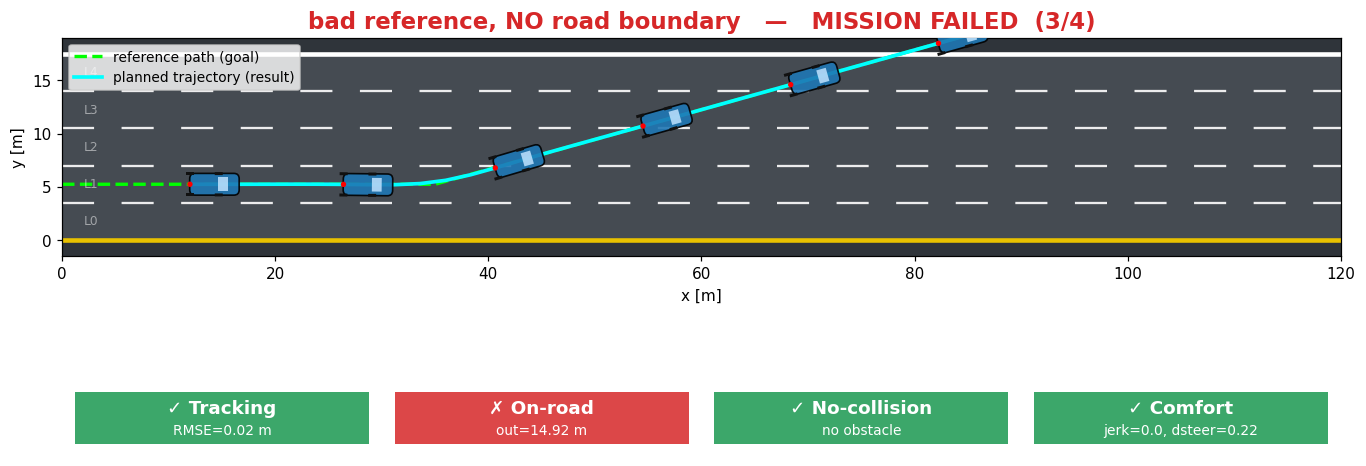

In [74]:
res = run({'track':15, 'heading':8, 'comfort':8}, scenario='badref',
          use_road=False, title='bad reference, NO road boundary')

### 실패 ④ 의 해결 — 도로 경계를 **제약으로** 켜기
같은 나쁜 reference라도, 도로 경계 제약을 켜면(`use_road=True`) planner는
*"초록선을 따라가고 싶지만 도로는 못 벗어난다"* 며 트랙 안에 머뭅니다.

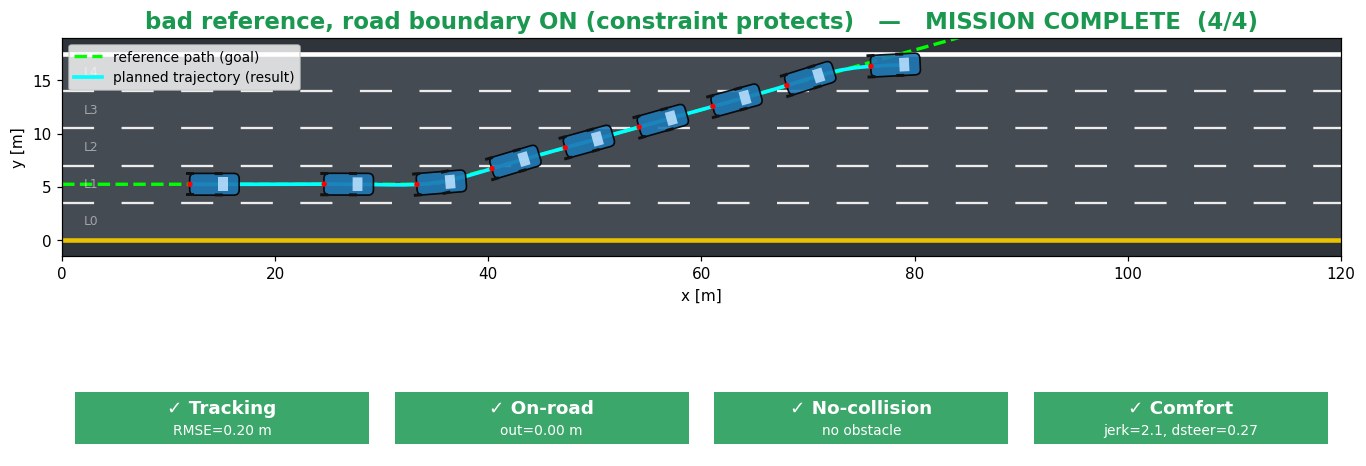

In [75]:
res = run({'track':15, 'heading':8, 'comfort':8}, scenario='badref',
          use_road=True, title='bad reference, road boundary ON (constraint protects)')

**중요**: **hard 제약은 나쁜 목표(soft)로부터 우리를 지켜줍니다.** 핵심은 On-road 가 ✗→✓ 로 바뀌는 부분입니다.
Tracking 점수는 horizon과 threshold에 따라 통과할 수도 있지만, planner가 soft 목표보다 hard safety를 우선한다는 점을 확인하세요.


---
# 수강생 실습 — 실패 Case를 직접 고쳐보기

이제 강사가 보여준 실패 상황을 수강생이 case별로 다시 고쳐 봅니다.
각 셀의 `____`를 숫자 또는 `True`/`False`로 바꾼 뒤 실행하세요.

진행 방식은 다음과 같습니다.

1. 실패 원인을 하나만 수정
2. `run()`을 실행해 결과에서 어떤 항목이 바뀌는지 확인
3. `cost`로 고칠 문제인지, `constraint`로 막아야 할 문제인지 판단

추천값을 바로 맞히는 것보다, 값을 조금씩 바꾸며 빨간 항목이 왜 바뀌는지 보는 것이 더 중요합니다! 


## 실습 Case 1 — reference를 따라가도록 weight 수정하기

강사 시연의 실패 ①과 같은 상황입니다. `track`, `heading`이 0이면 초록 reference를 따라갈 이유가 없습니다.
`curve` 시나리오에서 Tracking이 초록이 되도록 두 weight를 채워 보세요.


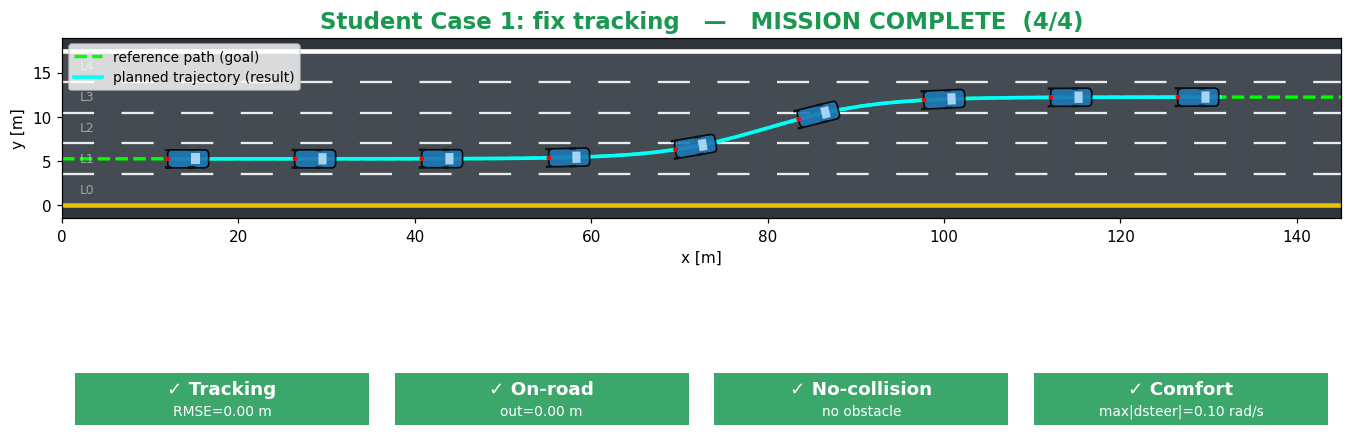

In [ ]:
# TODO: ____ 를 숫자로 바꾸세요. 예: 5, 10, 15 ...
W_case1 = {
    'track':   ____,   # reference와의 y 오차를 줄이는 힘       @@정답: 10
    'heading': ____,   # reference 방향과 정렬하는 힘           @@정답: 10
    'comfort': 0.0,
}
res_case1 = run(W_case1, scenario='curve', title='Student Case 1: fix tracking')

## 실습 Case 2 — 휙휙 꺾는 planner 부드럽게 만들기

강사 시연의 실패 ②와 같은 상황입니다. `comfort`가 너무 작으면 solver가 조향을 급하게(δ̇ 크게) 씁니다.
이번에는 `track`, `heading`은 고정하고 `comfort`만 조절해 Comfort가 초록이 되도록 해보세요.


In [ ]:
# TODO: comfort ____ 를 숫자로 바꾸세요.
W_case2 = {
    'track':   10.0,
    'heading': 8.0,
    'comfort': ____,   # (hint)너무 작으면 급격히 변함, 너무 크면 둔해짐       @@정답: 20
}
res_case2 = run(W_case2, scenario='mission', title='Student Case 2: fix comfort')
show_profiles(res_case2)

## 실습 Case 3 — 장애물을 뚫고 가는 planner 막기

강사 시연의 실패 ③과 같은 상황입니다. 충돌 회피는 cost가 아니라 hard constraint로 막아야 합니다.
아래 빈칸을 채워 `No-collision`을 초록으로 바꾸세요.


In [ ]:
# TODO: use_collision ____ 를 True 또는 False로 바꾸세요.
W_case3 = {'track':8.0, 'heading':12.0, 'comfort':8}
res_case3 = run(W_case3, scenario='avoid', use_collision=____,   # @@정답: True
                title='Student Case 3: collision constraint')

## 실습 Case 4 — 도로 밖 reference가 들어왔을 때 제약 없이 재현하기

강사 시연의 실패 ④를 먼저 직접 재현합니다. `badref`는 reference 자체가 도로 밖으로 향합니다.
도로 경계 constraint를 끄면 어떤 항목이 빨개지는지 확인하세요.


In [ ]:
# TODO: 강사 실패 상황을 재현하려면 use_road ____ 를 무엇으로 두어야 할까요?
W_case4 = {'track':15.0, 'heading':8.0, 'comfort':8}
res_case4 = run(W_case4, scenario='badref', use_road=____,   # @@정답: False  (도로 제약을 끄면 reference 를 따라 도로 밖으로 나감)
                title='Student Case 4: bad reference without road constraint')

## 실습 Case 5 — 같은 bad reference를 hard constraint로 보호하기

이번에는 같은 `badref`에서 도로 경계 constraint를 켭니다.
목표 자체가 나쁘기 때문에 Tracking은 여전히 실패할 수 있지만, On-road가 어떻게 바뀌는지 확인하세요.
이 case는 **soft cost가 틀렸을 때 hard constraint가 안전을 지키는 역할**을 보여줍니다.


In [ ]:
# TODO: use_road ____ 를 True 또는 False로 바꾸세요.
W_case5 = {'track':15.0, 'heading':8.0, 'comfort':8}
res_case5 = run(W_case5, scenario='badref', use_road=____,          # @@정답: True  (도로 제약을 켜면 도로 안에 머무름)
                title='Student Case 5: road constraint protects')

---
# 종합 미션 — 비용과 제약을 함께 맞추기

마지막으로 `mission` 시나리오에서 4/4 초록을 만드세요.
이번 셀에서는 weight 3개뿐 아니라, 충돌 제약과 도로 제약이 켜져 있어야 하는지도 직접 채웁니다.


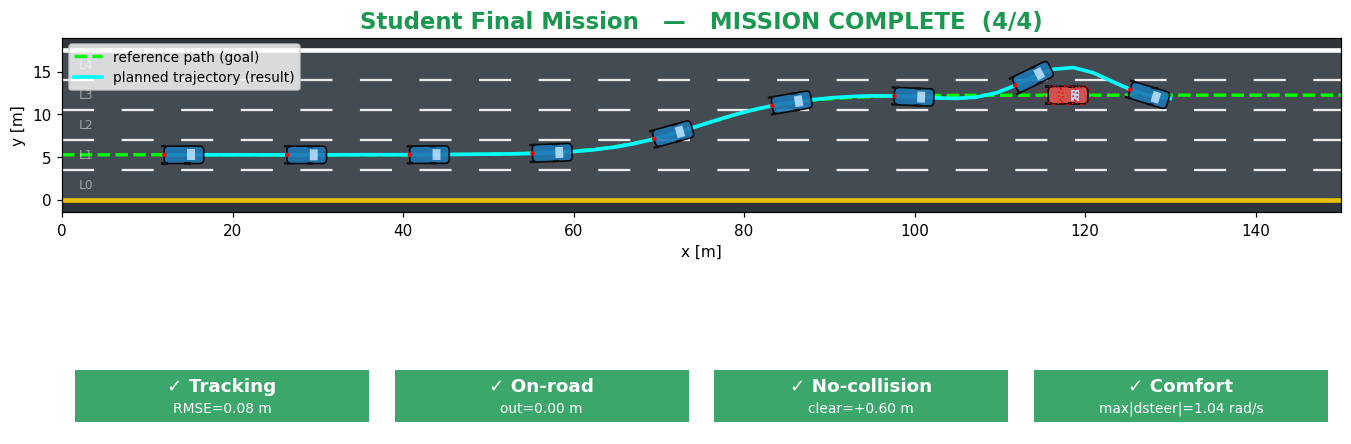

In [ ]:
# TODO: 모든 ____ 를 채워 4/4 초록을 만들어 보세요.
W_final = {
    'track':   ____,   # @@정답: 10
    'heading': ____,   # @@정답: 10
    'comfort': ____,   # @@정답: 20
}
res = run(W_final, scenario='mission',
          use_collision=____,   # @@정답: True
          use_road=____,        # @@정답: True
          title='Student Final Mission')

4/4 초록이 떴다면 아래 셀로 제어 프로파일도 확인해 보세요.
가속도와 조향각 그래프가 너무 날카로우면 `comfort`를 조금 키우고, reference를 못 따라가면 `track` 또는 `heading`을 조절해 보세요.


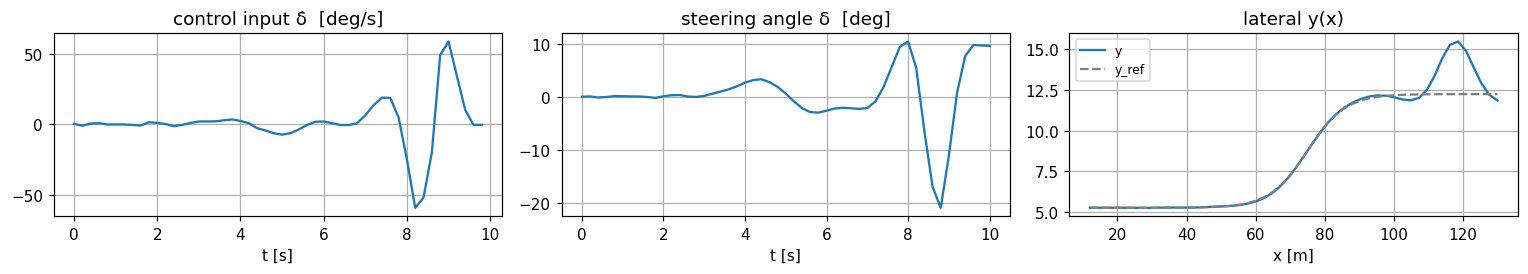

In [ ]:
show_profiles(res)
# 주행 애니메이션도 보고 싶다면 아래 주석을 푸세요:
# animate(res)


---
# (심화) 비용 항을 직접 짜보기

solver가 최소화하는 비용 항을 직접 구현해 봅니다.
빈칸을 채우면, 여러분의 비용 함수가 엔진의 `cost_fn()` 과 같은 값을 내는지 자가 채점합니다.

**힌트**
- state: `s[:,1]`=y, `s[:,2]`=heading θ, `s[:,3]`=조향각 δ
- control input: `u` = δ̇ (조향 변화율)
- 평균 제곱 = `np.mean(error**2)` , `np.mean(u**2)`
- trajectory rollout = `simulate(z, x0)`

In [ ]:
def my_tracking_cost(s, yref):
    # TODO 1: y_error = 현재 y - reference y
    y_error = ____                       # @@정답: s[:, 1] - yref(s[:, 0])
    # TODO 2: 오차 제곱의 평균 (hint) np.mean(___**2)
    return ____                          # @@정답: np.mean(y_error ** 2)

def my_heading_cost(s, dyref):
    # TODO 3: theta_error = 현재 heading - reference heading
    theta_error = ____                   # @@정답: s[:, 2] - thetaref(dyref, s[:, 0])
    # TODO 4: 오차 제곱의 평균
    return ____                          # @@정답: np.mean(theta_error ** 2)

def my_steer_cost(s):
    # TODO 5: 조향각 δ 는 s[:,3]. δ^2 의 평균
    return ____                          # @@정답: np.mean(s[:, 3] ** 2)

def my_comfort_cost(u):
    # TODO 6: control input δ̇(=u) 의 제곱 평균   (힌트: np.mean(u**2))
    return ____                          # @@정답: np.mean(u ** 2)

def my_total_cost(z, W, yref, dyref, x0):
    # TODO 7: bicycle model 로 trajectory rollout   (힌트: simulate(z, x0))
    s = ____                             # @@정답: simulate(z, x0)
    # TODO 8~11: 엔진 cost_fn 과 같은 weighted sum  (STEER_WEIGHT 는 고정 weight)
    return (W['track']*____ +            # @@정답: my_tracking_cost(s, yref)
            W['heading']*____ +          # @@정답: my_heading_cost(s, dyref)
            STEER_WEIGHT*____ +          # @@정답: my_steer_cost(s)
            W['comfort']*____)           # @@정답: my_comfort_cost(z)

# ---- 자가 채점 ----
yref,dyref,obs,xv = make_scenario('mission')
x0_test = np.array([12.0, LANE[1], 0.0, 0.0])     # x, y, θ, δ
z_test = warm_start(x0_test, yref, dyref)          # δ̇ 시퀀스
u_test = z_test
s_test = simulate(u_test, x0_test)
W_test = {'track':10.0,'heading':8.0,'comfort':3.0}

try:
    mine = {
        'track':   my_tracking_cost(s_test, yref),
        'heading': my_heading_cost(s_test, dyref),
        'steer':   my_steer_cost(s_test),
        'comfort': my_comfort_cost(u_test),
        'total':   my_total_cost(z_test, W_test, yref, dyref, x0_test),
    }
    ref_terms,_,_ = cost_terms_from_controls(z_test, yref, dyref, x0_test)
    ref = {
        'track':   ref_terms['track'],
        'heading': ref_terms['heading'],
        'steer':   ref_terms['steer'],
        'comfort': ref_terms['comfort'],
        'total':   cost_fn(z_test, W_test, yref, dyref, x0_test),
    }
    for key in ['track','heading','steer','comfort','total']:
        ok = np.isclose(mine[key], ref[key])
        print(('✅' if ok else '❌'), f'{key:<8s}', f'mine={mine[key]:.6f}', f'ref={ref[key]:.6f}')
except Exception as e:
    print('아직 빈칸(____)이 남아 있습니다:', e)

---
# 추가 학습 (빠른 분들용)

자유롭게 cost를 변경하며 실험해보세요. 

In [29]:
# (자유 실험 공간)
# 예: res = run({'track':8,'heading':12,'comfort':1.5}, scenario='avoid', title='avoid challenge')



---
## 정리

- **Bicycle model**은 `kinematic_bicycle_step()`과 `simulate()`에서 trajectory를 만듭니다.
- **Cost (soft)** = 추종(`track`, `heading`) + 승차감(`comfort`). weight로 planner의 성격을 정합니다.
- **Constraint (hard)** = 충돌·도로·제어 한계. 무슨 일이 있어도 지켜야 하는 안전선입니다.
- `run()`은 이제 최적화 이론 코드가 아니라, `optimize()` 결과를 보여주는 wrapper입니다.
- 이 구조가 그대로 **MPC**로 확장되어 매 순간 다시 풀리며 실제 차를 움직입니다.
